# 03: Fault detection and alarm demo

The twin watches the plant minute by minute. For every reading it asks: *what should this instrument show, given the current feed and setpoints?* When reality and expectation drift apart, it raises an alarm and suggests a likely cause.

**Part A (needs DWSIM):** runs six 12-hour scenarios through the rigorous model, so even the faulty plant behaves physically correctly.

| Scenario | What happens | What the operator should learn |
|---|---|---|
| S0 Healthy | Normal day: feed temperature rises in the afternoon, feed flow wanders ±4% | Nothing. No alarms expected |
| S1 Compressor wear | Compressor efficiency falls from 75% to 69% over 6 h | Compressor performance is dropping, schedule an inspection |
| S2 Air-cooler fouling | Air-cooler outlet rises from 45 to 55 °C over 6 h | Pre-cooling is degrading and the chiller is working harder |
| S3 Chiller capacity loss | Chiller can't hold its 15 °C setpoint, drifting up to 27 °C | LPG output is falling because the chiller is struggling |
| S4 Pressure sensor drift | PT-101 reads up to 2 bar high (the plant itself is healthy) | Instrument problem, not process: check the transmitter |
| S5 Unsafe setpoint move | Operator warms the chiller and lowers pressure towards the failure region | Advisory, then alarm, *before* the deethanizer fails |

**Part B (no DWSIM needed):** adds realistic sensor noise, compares each reading with the twin's prediction, and runs the alarm logic (ISA-18.2 style: priorities, on-delays, deadbands and a rationalized alarm list).

## 1. Settings

In [1]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

PROJECT_DIR = r"C:\Users\HomePC\LPG_Optimization_Project"
MODEL_DIR   = os.path.join(PROJECT_DIR, "models", "v2")
SCEN_DIR    = os.path.join(PROJECT_DIR, "data", "scenarios")
os.makedirs(SCEN_DIR, exist_ok=True)

RUN_DWSIM  = True          
DWSIM_PATH = r"C:\Users\HomePC\Downloads\DWSIM"
SIM_PATH   = r"C:\Users\HomePC\Downloads\LPG_Recovery_v2.dwxmz"

SURROGATE  = "nn"          
HOURS, STEP_MIN = 12, 1    
SEED = 7

# Operating point: the optimum for 100 kg/h LPG from notebook 02b
SP_CHILLER_C, SP_PRESSURE_BAR = 15.0, 25.625
NOMINAL_FEED_KGH, NOMINAL_EFF, NOMINAL_AC_C = 1000.0, 75.0, 45.0

## 2. Scenario definitions
Each scenario is a minute-by-minute table of what is *actually* happening in the plant: feed conditions, setpoints, and any hidden fault.

In [2]:
t = np.arange(0, HOURS * 60, STEP_MIN)          # minutes
h = t / 60.0
rng = np.random.default_rng(SEED)

def ramp(h, start, end, v0, v1):
    """Linear change from v0 to v1 between hours start and end, flat outside."""
    return v0 + (v1 - v0) * np.clip((h - start) / (end - start), 0, 1)

# Shared normal day: feed warms through the afternoon, flow wanders slowly
feed_t = 31 + 8 * np.exp(-((h - 7) / 3.0) ** 2)                       # 31 C morning, 39 C mid-afternoon
walk = np.cumsum(rng.normal(0, 0.004, len(t))); walk -= np.linspace(walk[0], walk[-1], len(t))
feed_kgh = NOMINAL_FEED_KGH * (1 + np.clip(walk, -0.04, 0.04))

def base():
    return pd.DataFrame({"time_min": t, "hour": h, "feed_kgh": feed_kgh, "feed_t_c": feed_t,
                         "sp_chiller_c": SP_CHILLER_C, "sp_pressure_bar": SP_PRESSURE_BAR,
                         "chiller_actual_c": SP_CHILLER_C, "comp_eff_pct": NOMINAL_EFF,
                         "ac_outlet_c": NOMINAL_AC_C, "pt_bias_bar": 0.0})

SCENARIOS = {}
s = base(); SCENARIOS["S0_healthy"] = (s, None)
s = base(); s["comp_eff_pct"] = ramp(h, 3, 9, 75, 69);                  SCENARIOS["S1_compressor_wear"] = (s, 3.0)
s = base(); s["ac_outlet_c"]  = ramp(h, 2, 8, 45, 55);                  SCENARIOS["S2_aircooler_fouling"] = (s, 2.0)
s = base(); s["chiller_actual_c"] = ramp(h, 4, 7, 15, 27);              SCENARIOS["S3_chiller_capacity"] = (s, 4.0)
s = base(); s["pt_bias_bar"]  = ramp(h, 5, 9, 0, 2.0);                  SCENARIOS["S4_pt101_drift"] = (s, 5.0)
s = base()
s["sp_chiller_c"] = s["chiller_actual_c"] = ramp(h, 2, 10, 15, 44)
s["sp_pressure_bar"] = ramp(h, 2, 10, SP_PRESSURE_BAR, 18.5);           SCENARIOS["S5_unsafe_move"] = (s, 2.0)

for name, (sc, onset) in SCENARIOS.items():
    print(f"{name:22s} fault onset: {'none' if onset is None else f'hour {onset:.0f}'}")

S0_healthy             fault onset: none
S1_compressor_wear     fault onset: hour 3
S2_aircooler_fouling   fault onset: hour 2
S3_chiller_capacity    fault onset: hour 4
S4_pt101_drift         fault onset: hour 5
S5_unsafe_move         fault onset: hour 2


## 3. Part A: run the scenarios in DWSIM
Uses the corrected flowsheet and the same 1.3 × minimum reflux rule as notebook 01b. A sensor drift (S4) doesn't change the plant, so S4 reuses S0's plant data.

In [3]:
if RUN_DWSIM:
    import sys
    from pythonnet import load
    load("coreclr")
    import clr
    os.chdir(DWSIM_PATH)
    if DWSIM_PATH not in sys.path:
        sys.path.append(DWSIM_PATH)
    for ref in ["CapeOpen", "DWSIM.Automation", "DWSIM.Interfaces", "DWSIM.GlobalSettings",
                "DWSIM.SharedClasses", "DWSIM.Thermodynamics"]:
        clr.AddReference(ref)
    from DWSIM.Automation import Automation3
    interf = Automation3(); sim = interf.LoadFlowsheet(SIM_PATH)
    obj = lambda tag: sim.GetFlowsheetSimulationObject(tag).GetAsObject()
    feed, comp, ac, chil, s1, s2 = (obj(x) for x in ["Raw_Associated_Gas", "C-1", "AC-1", "CL-1", "SCOL-1", "SCOL-2"])
    ENERGY_TAGS = {"Compressor_Power_kW": "E1", "Air_Cooler_Duty_kW": "E_AC1", "Chiller_Duty_kW": "E2",
                   "Deethanizer_Condenser_kW": "Q_Condenser", "Deethanizer_Reboiler_kW": "Q_Reboiler",
                   "Debutanizer_Condenser_kW": "E5", "Debutanizer_Reboiler_kW": "E6"}
    estreams = {k: obj(v) for k, v in ENERGY_TAGS.items()}
    st = {k: obj(v) for k, v in {"comp_out": "2", "air_cooled": "Air_Cooled_Gas", "lpg": "Pure_LPG",
                                 "sales": "Sales_Gas_C1_C2"}.items()}

    def solve(row):
        feed.SetMassFlow(float(row.feed_kgh / 3600)); feed.SetTemperature(float(row.feed_t_c + 273.15))
        comp.POut = float(row.sp_pressure_bar * 1e5); comp.AdiabaticEfficiency = float(row.comp_eff_pct)
        ac.OutletTemperature = float(row.ac_outlet_c + 273.15)
        chil.OutletTemperature = float(row.chiller_actual_c + 273.15)
        s1.m_refluxratio = 20.0; s2.m_refluxratio = 20.0
        e = interf.CalculateFlowsheet2(sim)
        bad = lambda e: (e is not None and e.Count > 0) or str(s1.ErrorMessage or "").strip() or str(s2.ErrorMessage or "").strip()
        if bad(e):
            return {"status": "failed"}
        s1.m_refluxratio = 1.3 * float(s1.m_Rmin); s2.m_refluxratio = 1.3 * float(s2.m_Rmin)
        e = interf.CalculateFlowsheet2(sim)
        if bad(e):
            return {"status": "failed"}
        r = {k: abs(float(es.EnergyFlow)) for k, es in estreams.items()}
        r.update(LPG_kgh=float(st["lpg"].GetMassFlow()) * 3600,
                 Compressor_Discharge_T_C=float(st["comp_out"].GetTemperature()) - 273.15,
                 Air_Cooled_T_C=float(st["air_cooled"].GetTemperature()) - 273.15,
                 Deethanizer_Condenser_T_C=float(st["sales"].GetTemperature()) - 273.15, status="ok")
        return r

    t0 = time.time()
    for name, (sc, onset) in SCENARIOS.items():
        if name == "S4_pt101_drift":
            continue
        rows = []
        for i, row in enumerate(sc.itertuples()):
            rows.append(solve(row))
            if (i + 1) % 180 == 0:
                print(f"  {name}: {i + 1}/{len(sc)} ({time.time() - t0:.0f}s)")
        out = pd.concat([sc.reset_index(drop=True), pd.DataFrame(rows)], axis=1)
        out.to_csv(os.path.join(SCEN_DIR, f"{name}.csv"), index=False)
        print(f"{name}: done, {(out.status == 'failed').sum()} failed points")
    # S4: plant is healthy, only the pressure transmitter drifts
    s0 = pd.read_csv(os.path.join(SCEN_DIR, "S0_healthy.csv"))
    s0["pt_bias_bar"] = SCENARIOS["S4_pt101_drift"][0]["pt_bias_bar"].values
    s0.to_csv(os.path.join(SCEN_DIR, "S4_pt101_drift.csv"), index=False)
    comp.AdiabaticEfficiency = NOMINAL_EFF; ac.OutletTemperature = NOMINAL_AC_C + 273.15   # restore
    print(f"All scenarios saved to {SCEN_DIR} in {time.time() - t0:.0f}s")

  S0_healthy: 180/720 (62s)
  S0_healthy: 360/720 (114s)
  S0_healthy: 540/720 (166s)
  S0_healthy: 720/720 (216s)
S0_healthy: done, 0 failed points
  S1_compressor_wear: 180/720 (268s)
  S1_compressor_wear: 360/720 (321s)
  S1_compressor_wear: 540/720 (380s)
  S1_compressor_wear: 720/720 (431s)
S1_compressor_wear: done, 0 failed points
  S2_aircooler_fouling: 180/720 (483s)
  S2_aircooler_fouling: 360/720 (534s)
  S2_aircooler_fouling: 540/720 (584s)
  S2_aircooler_fouling: 720/720 (633s)
S2_aircooler_fouling: done, 0 failed points
  S3_chiller_capacity: 180/720 (682s)
  S3_chiller_capacity: 360/720 (731s)
  S3_chiller_capacity: 540/720 (781s)
  S3_chiller_capacity: 720/720 (829s)
S3_chiller_capacity: done, 0 failed points
  S5_unsafe_move: 180/720 (879s)
  S5_unsafe_move: 360/720 (929s)
  S5_unsafe_move: 540/720 (976s)
  S5_unsafe_move: 720/720 (990s)
S5_unsafe_move: done, 185 failed points
All scenarios saved to C:\Users\HomePC\LPG_Optimization_Project\data\scenarios in 994s


## 4. Part B: loading the twin
The twin uses only what a real plant would measure: feed flow (FT-001), feed temperature (TT-001), chiller outlet temperature (TT-102) and compressor discharge pressure (PT-101).

In [11]:
import joblib
cfg = json.load(open(os.path.join(MODEL_DIR, "config.json")))
INPUTS, TARGETS = cfg["inputs"], cfg["targets"]
feas = joblib.load(os.path.join(MODEL_DIR, "feasibility_boundary.pkl"))

if SURROGATE == "nn" and os.path.exists(os.path.join(MODEL_DIR, "nn_surrogate.pt")):
    import torch, torch.nn as nn
    ck = torch.load(os.path.join(MODEL_DIR, "nn_surrogate.pt"), map_location="cpu")
    nn_sc = joblib.load(os.path.join(MODEL_DIR, "nn_scalers.pkl"))
    hid = ck["hidden"]
    net = nn.Sequential(nn.Linear(ck["n_in"], hid[0]), nn.SiLU(), nn.Linear(hid[0], hid[1]), nn.SiLU(),
                        nn.Linear(hid[1], hid[2]), nn.SiLU(), nn.Linear(hid[2], ck["n_out"]))
    net.load_state_dict({k.replace("net.", "", 1): v for k, v in ck["state_dict"].items()}); net.eval()
    def twin_predict(X):
        with torch.no_grad():
            y = net(torch.tensor(nn_sc["x_scaler"].transform(X), dtype=torch.float32)).numpy()
        return pd.DataFrame(nn_sc["y_scaler"].inverse_transform(y), columns=TARGETS)
    print("Twin surrogate: PyTorch neural network")
else:
    g = joblib.load(os.path.join(MODEL_DIR, "gp_surrogate.pkl"))
    def twin_predict(X, chunk=500):
        Xs = g["x_scaler"].transform(X)
        y = np.vstack([g["gp"].predict(Xs[i:i + chunk]) for i in range(0, len(Xs), chunk)])
        return pd.DataFrame(g["y_scaler"].inverse_transform(y), columns=TARGETS)
    print("Twin surrogate: Gaussian process")

_P = np.linspace(15, 35, 801)
def margin_bar(t_c, p_bar):
    """Distance above the feasibility boundary (bar). Large positive = safe; negative = inside the failure region."""
    out = np.full(len(t_c), 99.0)
    for i, (tc, pb) in enumerate(zip(t_c, p_bar)):
        pf = feas.predict_proba(np.c_[np.full_like(_P, tc), _P])[:, 1]
        if pf[0] >= 0.5:
            out[i] = pb - _P[np.argmax(pf < 0.5)] if (pf < 0.5).any() else pb - 35.0
    return out

Twin surrogate: PyTorch neural network


## 5. Sensors
Each instrument gets realistic noise. Tags follow ISA-5.1. Section 9 shows how the alarms behave if the noise is larger.

In [5]:
# tag: (truth column, noise type, noise size)  ->  'rel' = fraction of reading, 'abs' = engineering units
SENSORS = {
    "FT-001": ("feed_kgh",                 "rel", 0.010),   # feed flow, kg/h
    "TT-001": ("feed_t_c",                 "abs", 0.50),    # feed temperature, C
    "PT-101": ("sp_pressure_bar",          "abs", 0.05),    # compressor discharge pressure, bar
    "TT-101": ("Compressor_Discharge_T_C", "abs", 0.50),    # compressor discharge temperature, C
    "JI-101": ("Compressor_Power_kW",      "rel", 0.005),   # compressor motor power, kW
    "TT-103": ("Air_Cooled_T_C",           "abs", 0.50),    # air-cooler outlet temperature, C
    "TT-102": ("chiller_actual_c",         "abs", 0.30),    # chiller outlet temperature, C
    "JI-102": ("Chiller_Duty_kW",          "rel", 0.020),   # chiller duty (refrigerant-side meter), kW
    "FT-301": ("LPG_kgh",                  "rel", 0.010),   # LPG product flow, kg/h
}
NOISE_SCALE = 1.0

def measure(truth, seed, noise_scale=NOISE_SCALE):
    r = np.random.default_rng(seed); m = pd.DataFrame({"time_min": truth.time_min, "hour": truth.hour})
    for tag, (col, kind, size) in SENSORS.items():
        x = truth[col].astype(float).values
        sd = size * noise_scale * (np.abs(x) if kind == "rel" else 1.0)
        m[tag] = x + r.normal(0, 1, len(x)) * sd
    m["PT-101"] += truth["pt_bias_bar"].values              # S4: transmitter drift
    m["SP-TT102"] = truth["sp_chiller_c"].values             # setpoints are known exactly
    m["plant_ok"] = truth["status"].values == "ok"
    return m

## 6. Detection: compare every reading with the twin
For each monitored tag, the **residual** is measured minus predicted. It is divided by its normal spread (learned from the first 2 hours of the healthy day, like commissioning), then smoothed with an EWMA filter so single noisy readings don't trigger anything.

In [6]:
RESIDUAL_TAGS = {"JI-101": "Compressor_Power_kW", "TT-101": "Compressor_Discharge_T_C",
                 "JI-102": "Chiller_Duty_kW", "FT-301": "LPG_kgh"}
EWMA_LAMBDA = 0.05
EWMA_LIMIT = 4.0            # alarm when |EWMA| exceeds 4 x its own normal spread
CALIB_MIN = 120             # first 2 hours of S0 used to learn the normal residual spread

def residuals(meas):
    X = np.c_[meas["TT-102"], meas["PT-101"], meas["FT-001"], meas["TT-001"]]
    pred = twin_predict(X)
    res = pd.DataFrame({"time_min": meas.time_min})
    for tag, col in RESIDUAL_TAGS.items():
        res[tag] = meas[tag].values - pred[col].values
        res[f"pred_{tag}"] = pred[col].values
    res.loc[~meas["plant_ok"].values, list(RESIDUAL_TAGS)] = np.nan    # no reading when the plant has tripped
    return res

def ewma(x, lam=EWMA_LAMBDA):
    out, z = np.empty(len(x)), 0.0
    for i, v in enumerate(x):
        z = z if np.isnan(v) else lam * v + (1 - lam) * z
        out[i] = z
    return out

# Commissioning: learn the normal spread of each residual on the healthy day
truth0 = pd.read_csv(os.path.join(SCEN_DIR, "S0_healthy.csv"))
EWMA_SD = np.sqrt(EWMA_LAMBDA / (2 - EWMA_LAMBDA))
def commission(noise_scale=NOISE_SCALE, seed=100):
    """Learn each residual's normal bias and spread from the first 2 hours of a healthy day."""
    global BIAS, SPREAD
    res0 = residuals(measure(truth0, seed=seed, noise_scale=noise_scale))
    calib = res0[res0.time_min < CALIB_MIN]
    BIAS = {tag: calib[tag].mean() for tag in RESIDUAL_TAGS}
    SPREAD = {tag: calib[tag].std() for tag in RESIDUAL_TAGS}
commission()
print("Normal residual spread (1 standard deviation):")
for tag in RESIDUAL_TAGS:
    print(f"  {tag}: {SPREAD[tag]:.3f}   (bias {BIAS[tag]:+.3f})")

def scores(res):
    """Smoothed, normalized residual for each tag: about 0 when healthy, beyond +/-1 means an alarm."""
    return pd.DataFrame({tag: ewma(((res[tag] - BIAS[tag]) / SPREAD[tag]).values) / (EWMA_LIMIT * EWMA_SD)
                         for tag in RESIDUAL_TAGS})

Normal residual spread (1 standard deviation):
  JI-101: 0.369   (bias -0.030)
  TT-101: 0.826   (bias -0.054)
  JI-102: 0.813   (bias -0.126)
  FT-301: 1.699   (bias -0.024)


## 7. Alarm logic and rationalization (ISA-18.2)
Every alarm has a cause, a consequence, an operator action, a priority, and settings that stop it chattering. Diagnostic messages come from the **pattern** of residuals, not from any single tag.

| Alarm | Trigger | Priority | On-delay | Cause | Consequence | Operator action |
|---|---|---|---|---|---|---|
| FEAS-ADV | Margin to failure boundary < 1.5 bar (clears above 2.0) | Low (advisory) | 2 min | Warm chiller and/or low pressure | Deethanizer close to losing its feed | Lower chiller setpoint or raise pressure |
| FEAS-HI | Margin < 0.5 bar (clears above 1.0) | High | 1 min | As above, closer | Deethanizer upset imminent | Act now: restore pressure / chiller |
| TT-102 DEV | Chiller outlet > setpoint + 2 °C (clears below 1.5) | Medium | 5 min | Chiller cannot hold setpoint | Less LPG recovered | Check chiller, refrigerant charge, condenser |
| JI-101 PERF | Compressor power residual > limit | Medium | 10 min | Compressor efficiency loss (wear, fouling) | Higher fuel use per kg LPG | Plan inspection / wash |
| JI-102 PERF | Chiller duty residual > limit | Low | 10 min | Pre-cooling degraded (air-cooler fouling, hot ambient) | More refrigeration power | Inspect / clean air cooler AC-1 |
| FT-301 LOW | LPG residual < −limit | Medium | 10 min | Recovery lower than the twin expects | Lost product | Check separator and columns |
| PT-101 SUSPECT | Power, discharge temperature and LPG all read *lower* than predicted | Medium | 10 min | Pressure transmitter reading high | Twin and operator act on a false pressure | Check / recalibrate PT-101 |

In [9]:
def delayed(flag, minutes):
    """Alarm only after the condition has held for `minutes`; clear when it stops (simple on-delay)."""
    out, run = np.zeros(len(flag), bool), 0
    for i, f in enumerate(flag):
        run = run + 1 if f else 0
        out[i] = run >= minutes / STEP_MIN
    return out

def hysteresis(value, on, off):
    """Comes on above `on`, goes off below `off` (deadband stops chattering)."""
    out, state = np.zeros(len(value), bool), False
    for i, v in enumerate(value):
        state = (v > on) if not state else (v > off)
        out[i] = state
    return out

def alarms(meas, res):
    z = scores(res).fillna(0)
    margin = margin_bar(meas["TT-102"].values, meas["PT-101"].values)
    A = pd.DataFrame({"time_min": meas.time_min})
    A["FEAS-ADV"]   = delayed(hysteresis(-margin, -1.5, -2.0), 2)
    A["FEAS-HI"]    = delayed(hysteresis(-margin, -0.5, -1.0), 1)
    A["TT-102 DEV"] = delayed(hysteresis((meas["TT-102"] - meas["SP-TT102"]).values, 2.0, 1.5), 5)
    pt_suspect = (z["JI-101"] < -1) & (z["TT-101"] < -1) & (z["FT-301"] < -1)
    A["PT-101 SUSPECT"] = delayed(pt_suspect.values, 10)
    A["JI-101 PERF"] = delayed(((z["JI-101"] > 1) & (z["TT-101"] > 0)).values, 10)
    A["JI-102 PERF"] = delayed((z["JI-102"] > 1).values, 10)
    A["FT-301 LOW"]  = delayed(((z["FT-301"] < -1) & ~pt_suspect).values, 10) & ~A["TT-102 DEV"].values
    A["PLANT TRIP"]  = ~meas["plant_ok"].values                    # what happens without the twin
    A["margin_bar"] = margin
    for tag in RESIDUAL_TAGS:
        A[f"z_{tag}"] = z[tag].values
    return A

ALARM_COLS = ["FEAS-ADV", "FEAS-HI", "TT-102 DEV", "JI-101 PERF", "JI-102 PERF", "FT-301 LOW", "PT-101 SUSPECT"]

def first_on(A, col):
    on = A.loc[A[col], "time_min"]
    return None if on.empty else float(on.iloc[0])

## 8. Run all scenarios

In [12]:
EXPECTED = {"S0_healthy": [], "S1_compressor_wear": ["JI-101 PERF"], "S2_aircooler_fouling": ["JI-102 PERF"],
            "S3_chiller_capacity": ["TT-102 DEV"], "S4_pt101_drift": ["PT-101 SUSPECT"],
            "S5_unsafe_move": ["FEAS-ADV", "FEAS-HI"]}
RUNS, summary = {}, []
for k, (name, (sc, onset)) in enumerate(SCENARIOS.items()):
    truth = pd.read_csv(os.path.join(SCEN_DIR, f"{name}.csv"))
    meas = measure(truth, seed=200 + k)
    res = residuals(meas)
    A = alarms(meas, res)
    RUNS[name] = (truth, meas, res, A)
    raised = [c for c in ALARM_COLS if A[c].any()]
    trip = first_on(A, "PLANT TRIP")
    row = {"Scenario": name, "Alarms raised": ", ".join(raised) or "none",
           "Expected": ", ".join(EXPECTED[name]) or "none",
           "Unexpected alarms": ", ".join(sorted(set(raised) - set(EXPECTED[name]))) or "none"}
    if EXPECTED[name] and name != "S5_unsafe_move":
        t_det = first_on(A, EXPECTED[name][0])
        row["Detected after (min)"] = None if t_det is None else round(t_det - onset * 60)
    if name == "S1_compressor_wear" and row.get("Detected after (min)") is not None:
        row["Fault size at detection"] = f"efficiency {np.interp(first_on(A, 'JI-101 PERF'), truth.time_min, truth.comp_eff_pct):.1f}% (from 75%)"
    if name == "S2_aircooler_fouling" and row.get("Detected after (min)") is not None:
        row["Fault size at detection"] = f"air-cooler outlet {np.interp(first_on(A, 'JI-102 PERF'), truth.time_min, truth.ac_outlet_c):.1f} C (from 45)"
    if name == "S3_chiller_capacity" and row.get("Detected after (min)") is not None:
        row["Fault size at detection"] = f"chiller outlet {np.interp(first_on(A, 'TT-102 DEV'), truth.time_min, truth.chiller_actual_c):.1f} C (setpoint 15)"
    if name == "S4_pt101_drift" and row.get("Detected after (min)") is not None:
        row["Fault size at detection"] = f"PT-101 reading {np.interp(first_on(A, 'PT-101 SUSPECT'), truth.time_min, truth.pt_bias_bar):+.2f} bar high"
    if name == "S5_unsafe_move":
        adv, hi = first_on(A, "FEAS-ADV"), first_on(A, "FEAS-HI")
        row["Fault size at detection"] = (f"warning {trip - adv:.0f} min before the deethanizer fails (advisory), "
                                          f"{trip - hi:.0f} min (high alarm)") if trip and adv and hi else "plant did not trip"
    summary.append(row)
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 80)
summary = pd.DataFrame(summary)
summary

,Scenario,Alarms raised,Expected,Unexpected alarms,Detected after (min),Fault size at detection
0,S0_healthy,none,none,none,NaN,NaN
1,S1_compressor_wear,JI-101 PERF,JI-101 PERF,none,58.0,efficiency 74.0% (from 75%)
2,S2_aircooler_fouling,JI-102 PERF,JI-102 PERF,none,41.0,air-cooler outlet 46.1 C (from 45)
3,S3_chiller_capacity,TT-102 DEV,TT-102 DEV,none,30.0,chiller outlet 17.0 C (setpoint 15)
4,S4_pt101_drift,PT-101 SUSPECT,PT-101 SUSPECT,none,71.0,PT-101 reading +0.59 bar high
5,S5_unsafe_move,"FEAS-ADV, FEAS-HI","FEAS-ADV, FEAS-HI",none,NaN,"warning 28 min before the deethanizer fails (advisory), 14 min (high alarm)"


In [13]:
# Alarm load (ISA-18.2 suggests about 6 or fewer new alarms per operator per hour on average)
loads = {name: int(sum((A[c] & ~A[c].shift(1, fill_value=False)).sum() for c in ALARM_COLS)) for name, (_, _, _, A) in RUNS.items()}
print("New alarms per 12-hour scenario:", loads)
print(f"Worst case: {max(loads.values()) / HOURS:.2f} alarms per hour")

New alarms per 12-hour scenario: {'S0_healthy': 0, 'S1_compressor_wear': 1, 'S2_aircooler_fouling': 1, 'S3_chiller_capacity': 1, 'S4_pt101_drift': 1, 'S5_unsafe_move': 3}
Worst case: 0.25 alarms per hour


### Plots

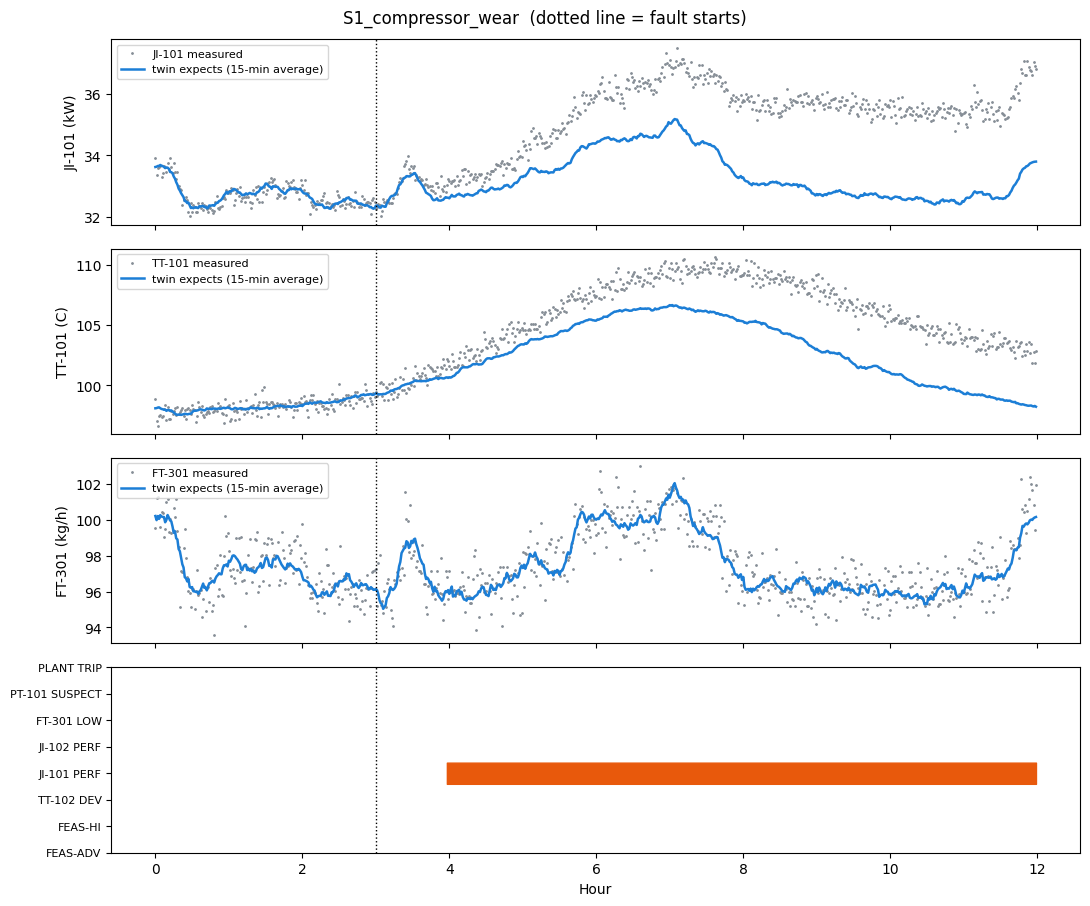

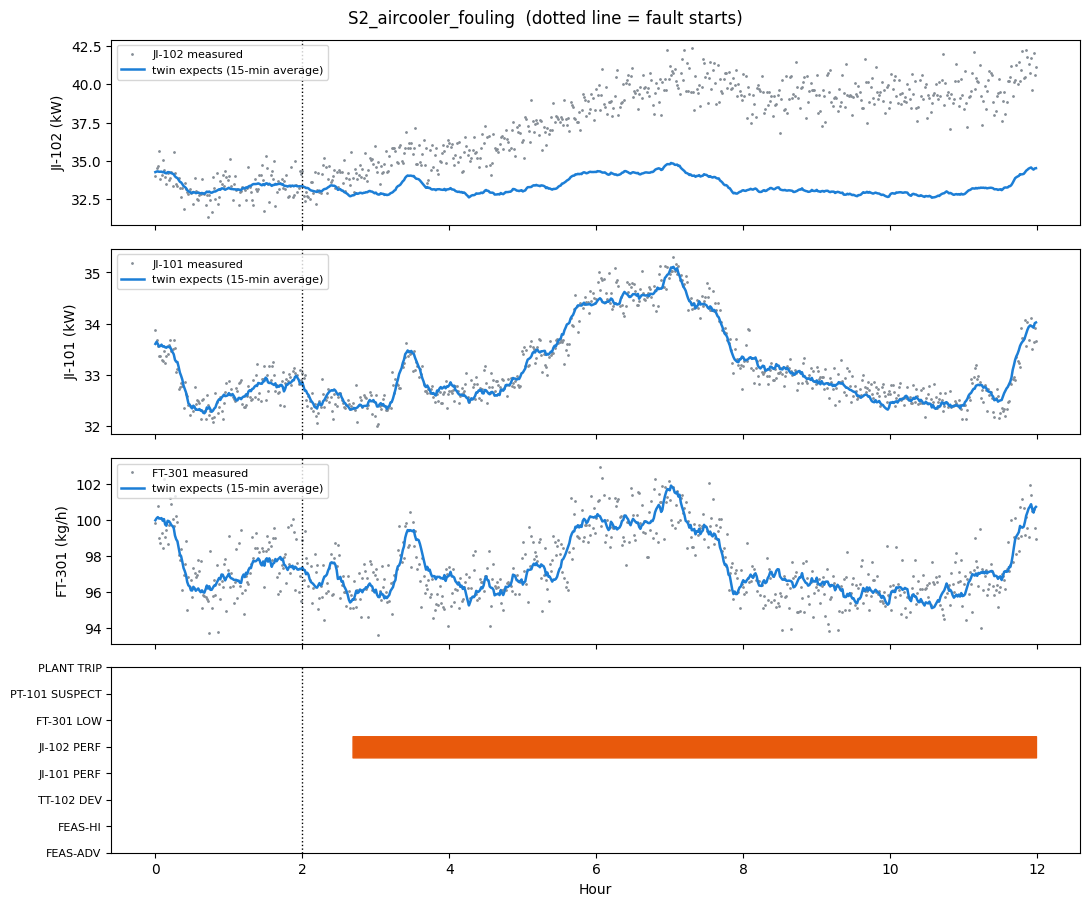

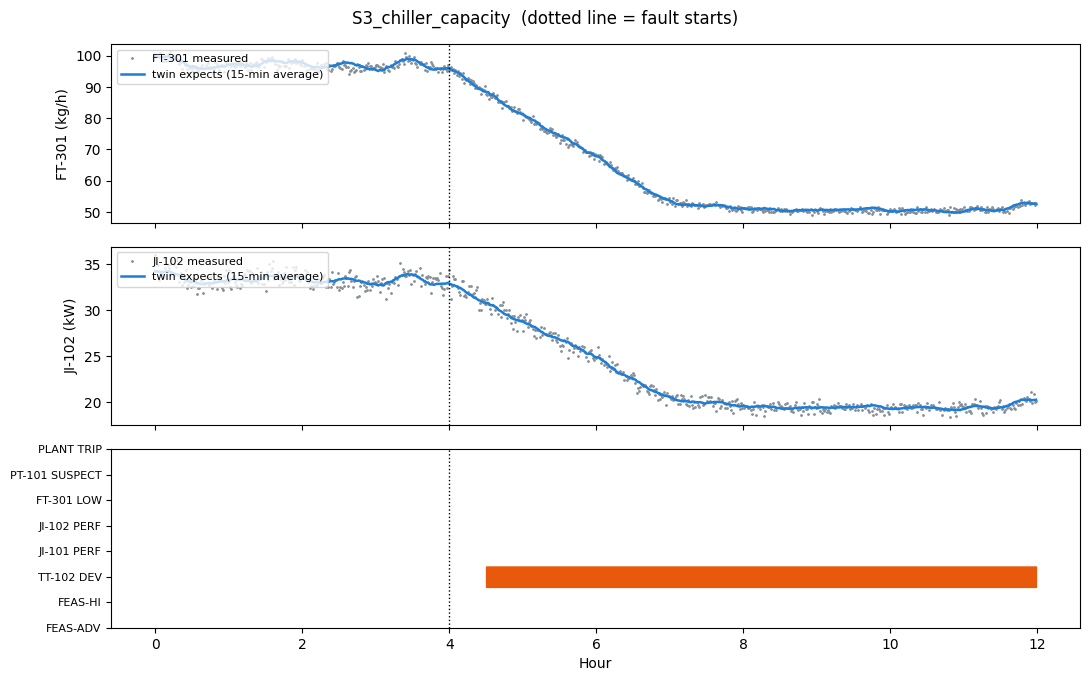

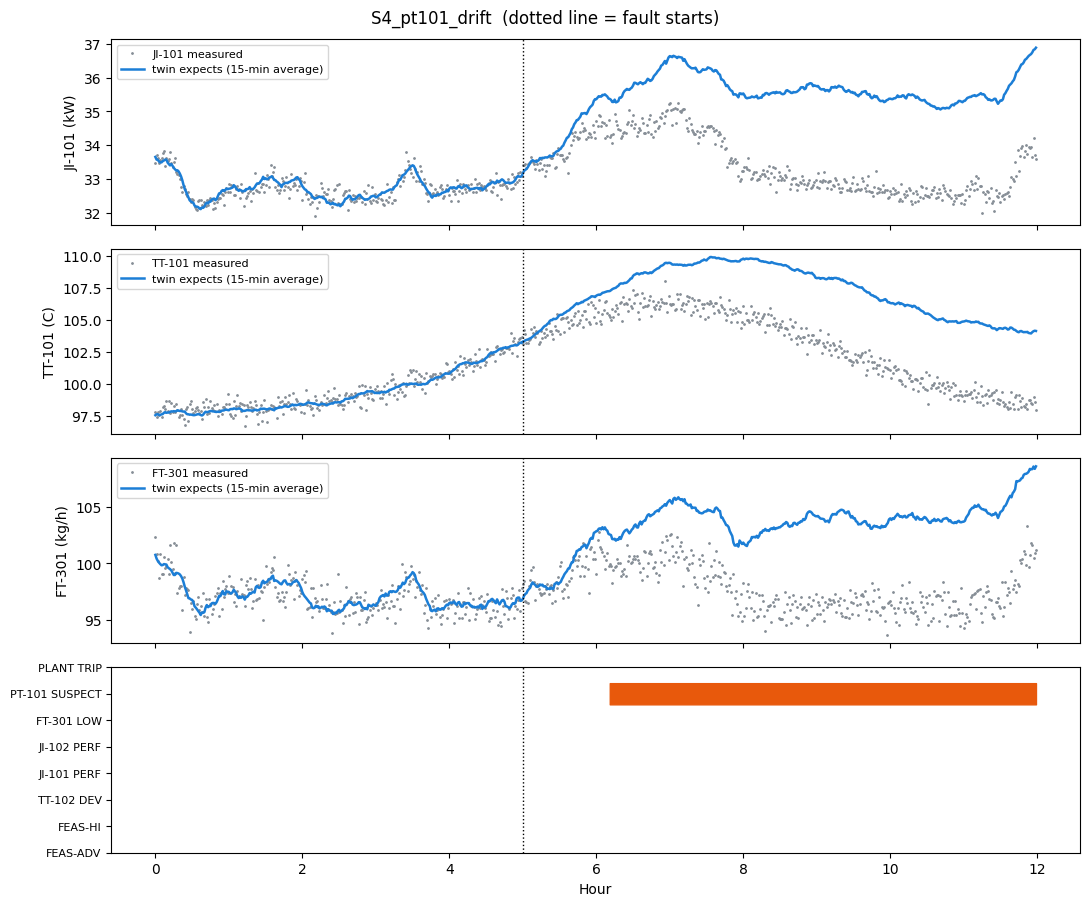

In [14]:
UNITS = {"JI-101": "kW", "TT-101": "C", "JI-102": "kW", "FT-301": "kg/h"}
def show(name, tags=("JI-101", "JI-102", "FT-301")):
    truth, meas, res, A = RUNS[name]
    onset = SCENARIOS[name][1]
    fig, axes = plt.subplots(len(tags) + 1, 1, figsize=(11, 2.3 * (len(tags) + 1)), sharex=True)
    for ax, tag in zip(axes, tags):
        ax.plot(meas.hour, meas[tag], ".", ms=2, color="#868e96", label=f"{tag} measured")
        ax.plot(meas.hour, res[f"pred_{tag}"].rolling(15, center=True, min_periods=1).mean(), "-",
                color="#1c7ed6", lw=1.8, label="twin expects (15-min average)")
        ax.set_ylabel(f"{tag} ({UNITS[tag]})"); ax.legend(loc="upper left", fontsize=8)
    ax = axes[-1]
    for i, c in enumerate(ALARM_COLS):
        on = A[c].values
        ax.fill_between(meas.hour, i, i + 0.8, where=on, step="mid", color="#e8590c" if "FEAS" not in c else "#c92a2a")
    trip = A["PLANT TRIP"].values
    if trip.any():
        ax.fill_between(meas.hour, len(ALARM_COLS), len(ALARM_COLS) + 0.8, where=trip, step="mid", color="black")
    ax.set_yticks(np.arange(len(ALARM_COLS) + 1) + 0.4); ax.set_yticklabels(ALARM_COLS + ["PLANT TRIP"], fontsize=8)
    ax.set_xlabel("Hour")
    for a in axes:
        if onset is not None:
            a.axvline(onset, color="k", ls=":", lw=1)
    fig.suptitle(f"{name}  (dotted line = fault starts)"); plt.tight_layout(); plt.show()

show("S1_compressor_wear", tags=("JI-101", "TT-101", "FT-301"))
show("S2_aircooler_fouling", tags=("JI-102", "JI-101", "FT-301"))
show("S3_chiller_capacity", tags=("FT-301", "JI-102"))
show("S4_pt101_drift", tags=("JI-101", "TT-101", "FT-301"))

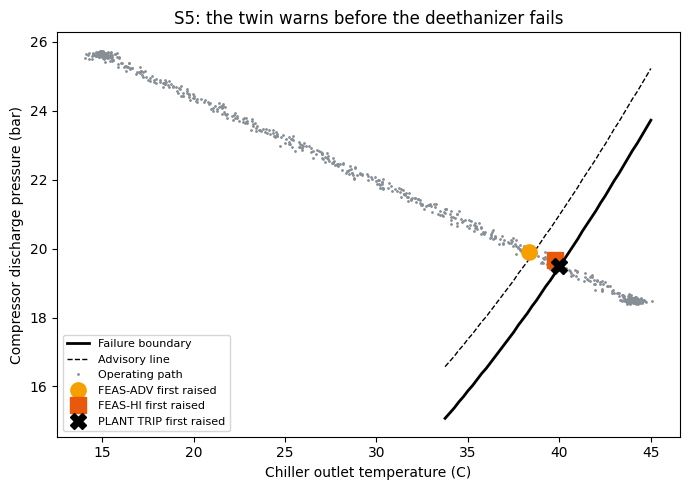

In [15]:
# S5: the operator's path across the operating window, with the alarm points marked
truth, meas, res, A = RUNS["S5_unsafe_move"]
fig, ax = plt.subplots(figsize=(7, 5))
tt = np.linspace(15, 45, 121); bnd = []
for tc in tt:
    pf = feas.predict_proba(np.c_[np.full_like(_P, tc), _P])[:, 1]
    bnd.append(_P[np.argmax(pf < 0.5)] if pf[0] >= 0.5 else np.nan)
bnd = np.array(bnd)
ax.plot(tt, bnd, "k-", lw=2, label="Failure boundary"); ax.plot(tt, bnd + 1.5, "k--", lw=1, label="Advisory line")
ax.plot(meas["TT-102"], meas["PT-101"], ".", ms=2, color="#868e96", label="Operating path")
for col, mk, c in [("FEAS-ADV", "o", "#f59f00"), ("FEAS-HI", "s", "#e8590c"), ("PLANT TRIP", "X", "black")]:
    i = A.index[A[col]]
    if len(i):
        ax.plot(meas.loc[i[0], "TT-102"], meas.loc[i[0], "PT-101"], mk, color=c, ms=11, label=f"{col} first raised")
ax.set_xlabel("Chiller outlet temperature (C)"); ax.set_ylabel("Compressor discharge pressure (bar)")
ax.set_title("S5: the twin warns before the deethanizer fails"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 9. Robustness: noisier instruments
Thresholds are always learned from the real instruments at commissioning. So for each noise level: re-commission, run ten healthy days (false alarms), and check how quickly compressor wear (S1) is caught.

In [16]:
truth1 = pd.read_csv(os.path.join(SCEN_DIR, "S1_compressor_wear.csv"))
for scale in [1.0, 2.0, 3.0]:
    commission(noise_scale=scale)
    fa = 0
    for rep in range(10):
        m = measure(truth0, seed=1000 + rep, noise_scale=scale)
        fa += int(alarms(m, residuals(m))[ALARM_COLS].any().sum())
    delays = []
    for rep in range(5):
        m = measure(truth1, seed=2000 + rep, noise_scale=scale)
        t1 = first_on(alarms(m, residuals(m)), "JI-101 PERF")
        delays.append(np.nan if t1 is None else t1 - 180)
    eff = [np.interp(d + 180, truth1.time_min, truth1.comp_eff_pct) for d in delays if not np.isnan(d)]
    print(f"Noise x{scale:.0f}: false alarms on 10 healthy days (120 h) = {fa} | compressor wear caught after "
          f"{np.nanmean(delays):.0f} min on average, at about {np.mean(eff):.1f}% efficiency")
commission()   # back to normal noise

Noise x1: false alarms on 10 healthy days (120 h) = 1 | compressor wear caught after 49 min on average, at about 74.2% efficiency
Noise x2: false alarms on 10 healthy days (120 h) = 1 | compressor wear caught after 76 min on average, at about 73.7% efficiency
Noise x3: false alarms on 10 healthy days (120 h) = 1 | compressor wear caught after 99 min on average, at about 73.4% efficiency


In [17]:
for name, (truth, meas, res, A) in RUNS.items():
    out = meas.merge(res, on="time_min").merge(A.drop(columns=["time_min"]), left_index=True, right_index=True)
    out.to_csv(os.path.join(SCEN_DIR, f"{name}_stream.csv"), index=False)
summary.to_csv(os.path.join(SCEN_DIR, "detection_summary.csv"), index=False)
print("Saved stream files and detection_summary.csv to", SCEN_DIR)

Saved stream files and detection_summary.csv to C:\Users\HomePC\LPG_Optimization_Project\data\scenarios
